# Part 3: Random Forest and K-Nearest Neighbors

This section uses the data preparation and train/test split from Part 1. The goal is to compare Random Forest (RF) and KNN, tune their hyperparameters, and document whether preprocessing and tuning improve performance. Spam is the positive class (`1`); non-spam is `0`.

We first compare majority-class, default RF, unscaled KNN, and scaled KNN models. We then tune RF and scaled KNN using average precision (AP). Five outer grouped folds with three inner grouped folds provide a separate evaluation of the tuning procedure. Thresholds are chosen using the outer out-of-fold predictions, before looking at test performance.

The final test set is used once after all settings are fixed. Results are saved under `results/part3/` and figures under `figures/part3/`. This notebook adds to the repository without changing Part 1 or its shared helpers.

## 1. Imports and setup


In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import RANDOM_STATE, TARGET, FIGURES_DIR, RESULTS_DIR
from src.data import load_spambase, clean_spambase, get_train_test

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

OUT = RESULTS_DIR / "part3"
FIG = FIGURES_DIR / "part3"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200})
COLORS = {"RF": "#2a78d6", "KNN": "#eb6834"}

def save_plot(name):
    plt.savefig(FIG / name, bbox_inches="tight")
    plt.show()
    plt.close()

## 2. Load the shared data split

Use `get_train_test()` so all group members evaluate on the same test set. The split uses 80% for training and 20% for testing, with seed 42.

Part 1 kept three pairs with identical features but opposite labels. We keep matching feature rows together during cross-validation and check that none appear on both sides of the train/test split. Exported row IDs refer to the cleaned dataframe, not the original file lines.

In [2]:
from sklearn.model_selection import StratifiedGroupKFold

raw = load_spambase()
data = clean_spambase(raw)
X_train, X_test, y_train, y_test = get_train_test()
assert TARGET not in X_train.columns
assert len(X_train) + len(X_test) == len(data)
assert set(X_train.index).isdisjoint(X_test.index)
assert np.isfinite(data.to_numpy()).all()
assert set(y_train.unique()) == {0, 1}
assert list(X_train.columns) == list(X_test.columns)

# Keep matching feature rows in the same CV fold.
group_ids = pd.Series(pd.factorize(pd.MultiIndex.from_frame(data.drop(columns=TARGET)))[0],
                      index=data.index)
groups = group_ids.loc[X_train.index].to_numpy()
test_groups = group_ids.loc[X_test.index].to_numpy()
assert set(groups).isdisjoint(test_groups), "Identical features cross train/test."

split = pd.DataFrame({"rows": [len(X_train), len(X_test)],
                      "non_spam": [(y_train == 0).sum(), (y_test == 0).sum()],
                      "spam": [y_train.sum(), y_test.sum()],
                      "spam_fraction": [y_train.mean(), y_test.mean()]},
                     index=["train", "test"])
display(split)
split.to_csv(OUT / "split_summary.csv")
assignment = pd.DataFrame({"cleaned_row_id": data.index, "group": group_ids,
                           "split": np.where(data.index.isin(X_train.index), "train", "test")})
assignment.to_csv(OUT / "split_assignment.csv", index=False)

outer_cv = list(StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE)
                .split(X_train, y_train, groups))
fold_id = np.zeros(len(X_train), dtype=int)
for fold, (train_idx, val_idx) in enumerate(outer_cv, 1):
    assert set(groups[train_idx]).isdisjoint(groups[val_idx])
    fold_id[val_idx] = fold
assert (fold_id > 0).all()
pd.DataFrame({"cleaned_row_id": X_train.index, "group": groups,
              "outer_fold": fold_id}).to_csv(OUT / "cv_assignments.csv", index=False)
print("Raw rows:", len(raw), "| Cleaned rows:", len(data), "| Features:", X_train.shape[1])
print("Train/test shared feature groups: 0; five grouped CV folds checked.")

,rows,non_spam,spam,spam_fraction
train,3368,2025,1343,0.398753
test,842,506,336,0.399050


Raw rows: 4601 | Cleaned rows: 4210 | Features: 57
Train/test shared feature groups: 0; five grouped CV folds checked.


## 3. Starting models

Random Forest combines many decision trees. KNN predicts from nearby training examples. We start with the default RF and five-neighbor KNN. We also compare KNN before and after scaling, since the feature ranges differ a lot. Scaling stays inside the pipeline so it is fitted on each training fold only.

The majority-class baseline always predicts non-spam. We report accuracy, precision, recall, F1, average precision (AP), and ROC-AUC. AP summarizes the precision–recall ranking; it is not trapezoidal PR area. A false positive flags legitimate mail as spam, while a false negative lets spam through. All labels use `probability >= threshold`, including ties.

In [3]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve, classification_report)

def evaluate(y, probability, threshold=.5):
    prediction = (np.asarray(probability) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, prediction),
            "precision": precision_score(y, prediction, zero_division=0),
            "recall": recall_score(y, prediction, zero_division=0),
            "f1": f1_score(y, prediction, zero_division=0),
            "average_precision": average_precision_score(y, probability),
            "roc_auc": roc_auc_score(y, probability),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

rf_default = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1)
knn_unscaled = KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=1)
knn_scaled = Pipeline([("scale", StandardScaler()),
                       ("knn", KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=1))])
starting_models = {"Majority baseline": DummyClassifier(strategy="most_frequent"),
                   "RF default": rf_default,
                   "KNN unscaled": knn_unscaled, "KNN scaled": knn_scaled}
cv_rows = []
oof = {}
for name, model in starting_models.items():
    probability = np.full(len(X_train), np.nan)
    for fold, (a, b) in enumerate(outer_cv, 1):
        fitted = clone(model).fit(X_train.iloc[a], y_train.iloc[a])
        probability[b] = fitted.predict_proba(X_train.iloc[b])[:, 1]
        cv_rows.append({"model": name, "fold": fold,
                        **evaluate(y_train.iloc[b], probability[b])})
    oof[name] = probability
    print(name, "finished")
cv_defaults = pd.DataFrame(cv_rows)
display(cv_defaults.groupby("model")[["average_precision", "accuracy", "precision", "recall", "f1"]]
        .agg(["mean", "std"]).round(4))

Majority baseline finished
RF default finished
KNN unscaled finished
KNN scaled finished


average_precision         accuracy         precision          recall              f1        
                               mean     std     mean     std      mean     std    mean     std    mean     std
model                                                                                                         
KNN scaled                   0.9072  0.0081   0.9020  0.0069    0.8950  0.0102  0.8548  0.0225  0.8742  0.0101
KNN unscaled                 0.7499  0.0176   0.7883  0.0132    0.7439  0.0231  0.7170  0.0346  0.7296  0.0185
Majority baseline            0.3988  0.0005   0.6012  0.0005    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
RF default                   0.9763  0.0107   0.9474  0.0104    0.9474  0.0175  0.9196  0.0213  0.9331  0.0134

## 4. Hyperparameter tuning

For RF, try different numbers of trees, tree depths, leaf sizes, and numbers of features considered at a split. For KNN, try different neighbor counts, voting weights, and distance measures. `p=1` uses Manhattan distance and `p=2` uses Euclidean distance [2–3].

Choose the settings with the highest mean validation AP. Both searches use the same five grouped folds and record all candidates. Accuracy and ROC-AUC are also saved. The test set is not used for these choices.

In [4]:
import json
from sklearn.model_selection import GridSearchCV, ParameterGrid

rf_grid = {"n_estimators": [100, 200], "max_depth": [None, 15],
           "min_samples_leaf": [1, 3], "max_features": ["sqrt", .5]}
knn_grid = {"knn__n_neighbors": [3, 5, 11, 21, 41],
            "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}
def score_accuracy(estimator, X, y):
    return accuracy_score(y, estimator.predict_proba(X)[:, 1] >= .5)

scoring = {"average_precision": "average_precision", "roc_auc": "roc_auc",
           "accuracy": score_accuracy}
search_specs = {"RF": (rf_default, rf_grid), "KNN": (knn_scaled, knn_grid)}
searches = {}
for name, (model, grid) in search_specs.items():
    print(name, "candidates:", len(ParameterGrid(grid)), flush=True)
    search = GridSearchCV(clone(model), grid, scoring=scoring, refit="average_precision",
                          cv=outer_cv, error_score="raise",
                          return_train_score=True)
    search.fit(X_train, y_train)
    searches[name] = search
    table = pd.DataFrame(search.cv_results_).sort_values("rank_test_average_precision")
    table.to_csv(OUT / f"{name.lower()}_grid_search.csv", index=False)
    print("Best parameters:", search.best_params_)
    print("Best mean search AP:", round(search.best_score_, 4))
    display(table[["params", "mean_test_average_precision", "std_test_average_precision",
                   "mean_train_average_precision", "mean_test_accuracy"]].head(5))

RF candidates: 16
Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
Best mean search AP: 0.9767


,params,mean_test_average_precision,std_test_average_precision,mean_train_average_precision,mean_test_accuracy
1,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.976730,0.010176,0.999996,0.947151
0,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.976309,0.009606,0.999995,0.947449
9,"{'max_depth': 15, 'max_features': 'sqrt', 'min...",0.975961,0.010017,0.998580,0.944775
8,"{'max_depth': 15, 'max_features': 'sqrt', 'min...",0.975267,0.010300,0.998578,0.944182
3,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.974709,0.010475,0.996476,0.940621


KNN candidates: 20
Best parameters: {'knn__n_neighbors': 21, 'knn__p': 1, 'knn__weights': 'distance'}
Best mean search AP: 0.9629


,params,mean_test_average_precision,std_test_average_precision,mean_train_average_precision,mean_test_accuracy
13,"{'knn__n_neighbors': 21, 'knn__p': 1, 'knn__we...",0.962943,0.008072,0.999995,0.906171
17,"{'knn__n_neighbors': 41, 'knn__p': 1, 'knn__we...",0.961389,0.006380,0.999995,0.892218
9,"{'knn__n_neighbors': 11, 'knn__p': 1, 'knn__we...",0.959099,0.006811,0.999995,0.914190
15,"{'knn__n_neighbors': 21, 'knn__p': 2, 'knn__we...",0.951058,0.006160,0.999996,0.906466
19,"{'knn__n_neighbors': 41, 'knn__p': 2, 'knn__we...",0.947015,0.003515,0.999996,0.903795


## 5. Cross-validation results

The best grid-search score can be optimistic because we chose it from several candidates. To check tuning separately, use five outer folds and repeat the search with three inner folds inside each outer training set [4]. Matching feature rows stay together in both sets of folds.

Each training row gets one prediction from a model that did not train or tune on that row. These are the out-of-fold (OOF) predictions. Compare the default and tuned models on the same outer folds. The standard deviations describe fold variation; no significance test was performed.

RF outer fold 1 finished
RF outer fold 2 finished
RF outer fold 3 finished
RF outer fold 4 finished
RF outer fold 5 finished
KNN outer fold 1 finished
KNN outer fold 2 finished
KNN outer fold 3 finished
KNN outer fold 4 finished
KNN outer fold 5 finished


average_precision         accuracy         precision          recall              f1         roc_auc        
                               mean     std     mean     std      mean     std    mean     std    mean     std    mean     std
model                                                                                                                         
KNN scaled                   0.9072  0.0081   0.9020  0.0069    0.8950  0.0102  0.8548  0.0225  0.8742  0.0101  0.9452  0.0068
KNN tuned                    0.9618  0.0083   0.8964  0.0106    0.9615  0.0141  0.7714  0.0337  0.8555  0.0179  0.9696  0.0069
KNN unscaled                 0.7499  0.0176   0.7883  0.0132    0.7439  0.0231  0.7170  0.0346  0.7296  0.0185  0.8481  0.0133
Majority baseline            0.3988  0.0005   0.6012  0.0005    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.5000  0.0000
RF default                   0.9763  0.0107   0.9474  0.0104    0.9474  0.0175  0.9196  0.0213  0.9331  0.0134  0.9812  0.0065
RF tuned                     0.9767  0.0114   0.9472  0.0102    0.9466  0.0168  0.9196  0.0227  0.9327  0.0132  0.9816  0.0065

,model,default_mean_ap,tuned_nested_mean_ap,mean_ap_change,sd_fold_ap_change
0,RF,0.97631,0.97673,0.00042,0.00096
1,KNN,0.90722,0.96184,0.05462,0.00933


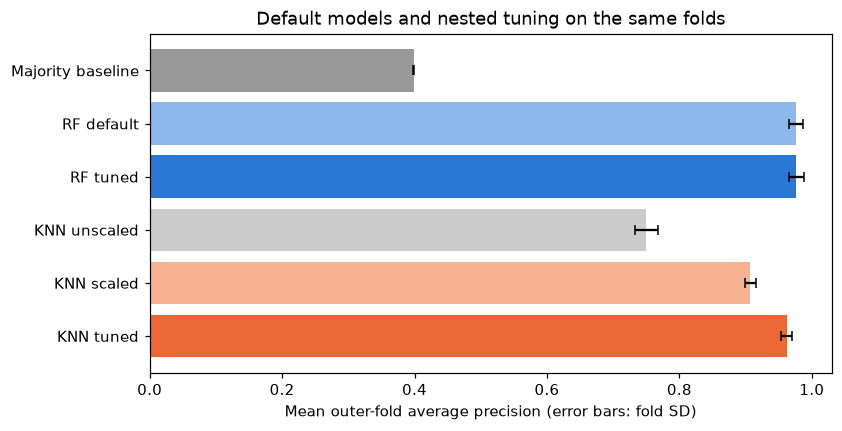

In [5]:
nested_rows = []
for name, (model, grid) in search_specs.items():
    probability = np.full(len(X_train), np.nan)
    for fold, (a, b) in enumerate(outer_cv, 1):
        inner_cv = list(StratifiedGroupKFold(3, shuffle=True, random_state=RANDOM_STATE)
                        .split(X_train.iloc[a], y_train.iloc[a], groups[a]))
        for inner_a, inner_b in inner_cv:
            assert set(groups[a][inner_a]).isdisjoint(groups[a][inner_b])
        search = GridSearchCV(clone(model), grid, scoring="average_precision",
                              cv=inner_cv, error_score="raise")
        search.fit(X_train.iloc[a], y_train.iloc[a])
        probability[b] = search.predict_proba(X_train.iloc[b])[:, 1]
        nested_rows.append({"model": name + " tuned", "fold": fold,
                            "best_params": json.dumps(search.best_params_),
                            **evaluate(y_train.iloc[b], probability[b])})
        print(name, "outer fold", fold, "finished", flush=True)
    assert np.isfinite(probability).all()
    oof[name + " tuned"] = probability

nested_results = pd.DataFrame(nested_rows)
nested_results.to_csv(OUT / "nested_cv_folds.csv", index=False)
all_cv = pd.concat([cv_defaults, nested_results], ignore_index=True)
all_cv.to_csv(OUT / "cv_fold_metrics.csv", index=False)
cv_summary = all_cv.groupby("model")[["average_precision", "accuracy", "precision", "recall", "f1", "roc_auc"]].agg(["mean", "std"])
cv_summary.to_csv(OUT / "cv_summary.csv")
display(cv_summary.round(4))
improvements = []
for name, before in [("RF", "RF default"), ("KNN", "KNN scaled")]:
    old = all_cv[all_cv.model == before].set_index("fold")
    new = all_cv[all_cv.model == name + " tuned"].set_index("fold")
    differences = new.average_precision - old.average_precision
    improvements.append({"model": name, "default_mean_ap": old.average_precision.mean(),
                         "tuned_nested_mean_ap": new.average_precision.mean(),
                         "mean_ap_change": differences.mean(), "sd_fold_ap_change": differences.std()})
improvements = pd.DataFrame(improvements)
improvements.to_csv(OUT / "tuning_improvements.csv", index=False)
display(improvements.round(5))
oof_table = pd.DataFrame(oof, index=X_train.index)
oof_table.insert(0, "true_label", y_train.to_numpy())
oof_table.insert(0, "outer_fold", fold_id)
oof_table.index.name = "cleaned_row_id"
oof_table.to_csv(OUT / "oof_probabilities.csv")

fig, ax = plt.subplots(figsize=(8, 4))
order = ["Majority baseline", "RF default", "RF tuned", "KNN unscaled", "KNN scaled", "KNN tuned"]
means = cv_summary.loc[order, ("average_precision", "mean")]
sd = cv_summary.loc[order, ("average_precision", "std")]
ax.barh(order, means, xerr=sd, color=["#999999", "#8db8ec", COLORS["RF"], "#cccccc", "#f5b391", COLORS["KNN"]], capsize=3)
ax.set(xlabel="Mean outer-fold average precision (error bars: fold SD)", xlim=(0, 1.03),
       title="Default models and nested tuning on the same folds")
ax.invert_yaxis()
save_plot("01_cv_comparison.png")

## 6. Tuning results

The KNN plot shows how validation AP changes with neighbor count, distance and weights. These are the full-training grid-search scores, separate from the nested evaluation above. The tables list the best parameter combinations and their training/validation scores.

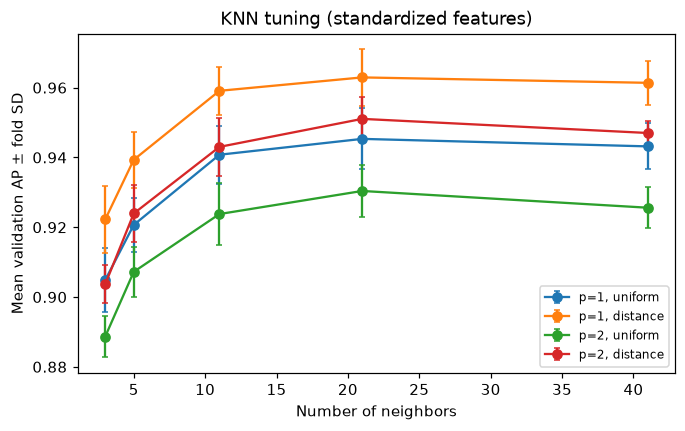

Chosen full-training parameters:
RF {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
KNN {'knn__n_neighbors': 21, 'knn__p': 1, 'knn__weights': 'distance'}
Scaling changed default KNN mean CV AP by +0.15733.


In [6]:
knn_search_table = pd.DataFrame(searches["KNN"].cv_results_)
fig, ax = plt.subplots(figsize=(7, 4))
for p in [1, 2]:
    for weights in ["uniform", "distance"]:
        subset = knn_search_table[(knn_search_table.param_knn__p == p) &
                                  (knn_search_table.param_knn__weights == weights)]
        subset = subset.sort_values("param_knn__n_neighbors")
        ax.errorbar(subset.param_knn__n_neighbors.astype(int), subset.mean_test_average_precision,
                    yerr=subset.std_test_average_precision, marker="o", capsize=2,
                    label=f"p={p}, {weights}")
ax.set(xlabel="Number of neighbors", ylabel="Mean validation AP ± fold SD",
       title="KNN tuning (standardized features)")
ax.legend(fontsize=8)
save_plot("02_knn_tuning.png")
print("Chosen full-training parameters:")
for name in searches:
    print(name, searches[name].best_params_)
scaling_change = (cv_summary.loc["KNN scaled", ("average_precision", "mean")] -
                  cv_summary.loc["KNN unscaled", ("average_precision", "mean")])
print(f"Scaling changed default KNN mean CV AP by {scaling_change:+.5f}.")

## 7. Decision thresholds

Start with a threshold of 0.5. Also try a more conservative policy: choose the highest OOF recall with precision of at least 98% and at least 20 spam flags. Ties prefer fewer false positives, then a higher threshold. If nothing qualifies, flag nothing.

This is an example policy, not a requirement or a guaranteed test precision. Set the thresholds before looking at test results. The OOF models were trained on smaller subsets, so the same threshold may behave differently on the final model [5].

RF locked threshold: 0.735
OOF selection metrics: {'accuracy': 0.9239904988123515, 'precision': 0.9805481874447391, 'recall': 0.8257632166790767, 'f1': 0.8965238480194018, 'average_precision': 0.9766531469737675, 'roc_auc': 0.9816061333112713, 'tn': 2003, 'fp': 22, 'fn': 234, 'tp': 1109}
KNN locked threshold: 0.6332263236578153
OOF selection metrics: {'accuracy': 0.8666864608076009, 'precision': 0.9806451612903225, 'recall': 0.6790766939687267, 'f1': 0.8024637043554773, 'average_precision': 0.9606136959980159, 'roc_auc': 0.9684671318128752, 'tn': 2007, 'fp': 18, 'fn': 431, 'tp': 912}


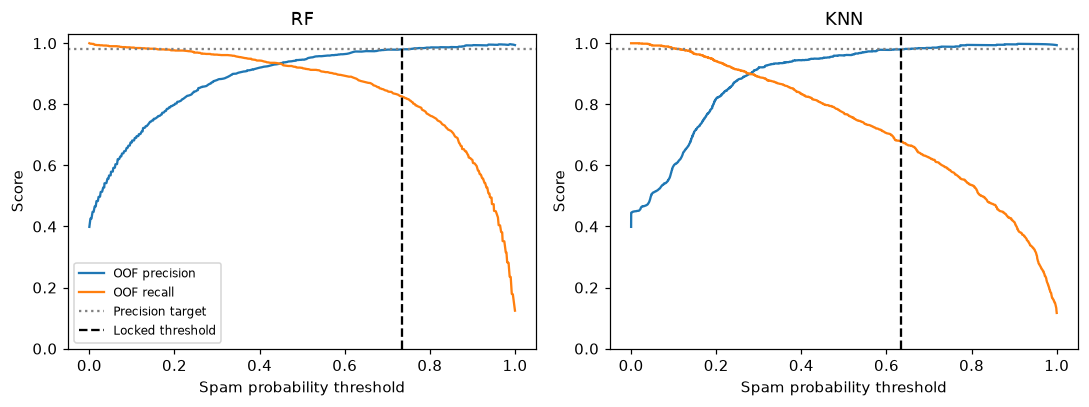

In [7]:
thresholds = {}
threshold_tables = {}

for model_name in ["RF", "KNN"]:
    probabilities = oof[model_name + " tuned"]
    precision_values, recall_values, candidates = precision_recall_curve(y_train, probabilities)
    threshold_rows = []

    for position in range(len(candidates)):
        threshold = candidates[position]
        spam_flags = probabilities >= threshold
        number_flagged = int(spam_flags.sum())
        false_positives = int((spam_flags & (y_train.to_numpy() == 0)).sum())

        threshold_rows.append({
            "threshold": threshold,
            "precision": precision_values[position],
            "recall": recall_values[position],
            "flagged": number_flagged,
            "fp": false_positives
        })

    table = pd.DataFrame(threshold_rows)
    enough_precision = table["precision"] >= 0.98
    enough_flags = table["flagged"] >= 20
    eligible = table[enough_precision & enough_flags]

    if eligible.empty:
        chosen_threshold = float(np.nextafter(1.0, 2.0))
    else:
        eligible = eligible.sort_values(
            ["recall", "fp", "threshold"], ascending=[False, True, False]
        )
        chosen_threshold = float(eligible.iloc[0]["threshold"])

    thresholds[model_name] = chosen_threshold
    threshold_tables[model_name] = table
    table.to_csv(OUT / f"{model_name.lower()}_oof_threshold_curve.csv", index=False)
    print(model_name, "locked threshold:", chosen_threshold)
    print("OOF selection metrics:", evaluate(y_train, probabilities, chosen_threshold))

# Save the settings before checking the test set.
chosen_parameters = {}
for model_name in ["RF", "KNN"]:
    chosen_parameters[model_name] = searches[model_name].best_params_

selection = {"random_state": RANDOM_STATE,
             "best_params": chosen_parameters, "thresholds": thresholds}
with open(OUT / "locked_settings.json", "w") as file:
    json.dump(selection, file, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for plot_number, model_name in enumerate(["RF", "KNN"]):
    ax = axes[plot_number]
    table = threshold_tables[model_name]
    ax.plot(table["threshold"], table["precision"], label="OOF precision")
    ax.plot(table["threshold"], table["recall"], label="OOF recall")
    ax.axhline(0.98, color="gray", linestyle=":", label="Precision target")
    ax.axvline(thresholds[model_name], color="black", linestyle="--", label="Locked threshold")
    ax.set_title(model_name)
    ax.set_xlabel("Spam probability threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.03)
axes[0].legend(fontsize=8)
fig.tight_layout()
save_plot("03_oof_thresholds.png")

## 8. Test results

The chosen models have been refitted on all training rows. Evaluate the fixed models at 0.5, then evaluate the tuned models at their conservative thresholds. Do not change the settings after seeing these results.

AP and ROC-AUC use probability scores, so they stay the same when only the threshold changes. The confusion matrices below show the tuned models under the two threshold policies.

In [8]:
test_rows = []
test_probabilities = {}
fitted_models = {}

for model_name in starting_models:
    model = clone(starting_models[model_name])
    model.fit(X_train, y_train)
    fitted_models[model_name] = model

for model_name in ["RF", "KNN"]:
    fitted_models[model_name + " tuned"] = searches[model_name].best_estimator_

for model_name in fitted_models:
    model = fitted_models[model_name]
    probabilities = model.predict_proba(X_test)[:, 1]
    test_probabilities[model_name] = probabilities

    result = {"model": model_name, "policy": "default 0.5", "threshold": 0.5}
    result.update(evaluate(y_test, probabilities))
    test_rows.append(result)

for model_name in ["RF", "KNN"]:
    probabilities = test_probabilities[model_name + " tuned"]
    threshold = thresholds[model_name]
    result = {"model": model_name + " tuned", "policy": "precision-target policy",
              "threshold": threshold}
    result.update(evaluate(y_test, probabilities, threshold))
    test_rows.append(result)

test_results = pd.DataFrame(test_rows)
test_results.to_csv(OUT / "test_metrics.csv", index=False)
display(test_results.round(4))

predictions = pd.DataFrame({"cleaned_row_id": X_test.index,
                            "true_label": y_test.to_numpy()})
for model_name in test_probabilities:
    probabilities = test_probabilities[model_name]
    predictions[model_name + "_probability"] = probabilities
    predictions[model_name + "_prediction"] = (probabilities >= 0.5).astype(int)

for model_name in ["RF", "KNN"]:
    probabilities = test_probabilities[model_name + " tuned"]
    predictions[model_name + "_conservative_prediction"] = (
        probabilities >= thresholds[model_name]
    ).astype(int)
predictions.to_csv(OUT / "test_predictions.csv", index=False)

reports = {}
for model_name in ["RF", "KNN"]:
    probabilities = test_probabilities[model_name + " tuned"]
    predicted_labels = (probabilities >= 0.5).astype(int)
    print(model_name, "tuned at threshold 0.5")
    print(classification_report(y_test, predicted_labels,
                               target_names=["Non-spam", "Spam"], zero_division=0))
    reports[model_name] = classification_report(
        y_test, predicted_labels, target_names=["Non-spam", "Spam"],
        zero_division=0, output_dict=True
    )
with open(OUT / "classification_reports.json", "w") as file:
    json.dump(reports, file, indent=2)

,model,policy,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,tn,fp,fn,tp
0,Majority baseline,default 0.5,0.5000,0.6010,0.0000,0.0000,0.0000,0.3990,0.5000,506,0,336,0
1,RF default,default 0.5,0.5000,0.9466,0.9369,0.9286,0.9327,0.9838,0.9896,485,21,24,312
2,KNN unscaled,default 0.5,0.5000,0.7838,0.7292,0.7292,0.7292,0.7563,0.8539,415,91,91,245
3,KNN scaled,default 0.5,0.5000,0.9133,0.9148,0.8631,0.8882,0.9269,0.9546,479,27,46,290
4,RF tuned,default 0.5,0.5000,0.9430,0.9364,0.9196,0.9279,0.9841,0.9897,485,21,27,309
5,KNN tuned,default 0.5,0.5000,0.9169,0.9618,0.8244,0.8878,0.9684,0.9802,495,11,59,277
6,RF tuned,precision-target policy,0.7350,0.9311,0.9929,0.8333,0.9061,0.9841,0.9897,504,2,56,280
7,KNN tuned,precision-target policy,0.6332,0.8919,0.9804,0.7440,0.8460,0.9684,0.9802,501,5,86,250


RF tuned at threshold 0.5
              precision    recall  f1-score   support

    Non-spam       0.95      0.96      0.95       506
        Spam       0.94      0.92      0.93       336

    accuracy                           0.94       842
   macro avg       0.94      0.94      0.94       842
weighted avg       0.94      0.94      0.94       842

KNN tuned at threshold 0.5
              precision    recall  f1-score   support

    Non-spam       0.89      0.98      0.93       506
        Spam       0.96      0.82      0.89       336

    accuracy                           0.92       842
   macro avg       0.93      0.90      0.91       842
weighted avg       0.92      0.92      0.92       842



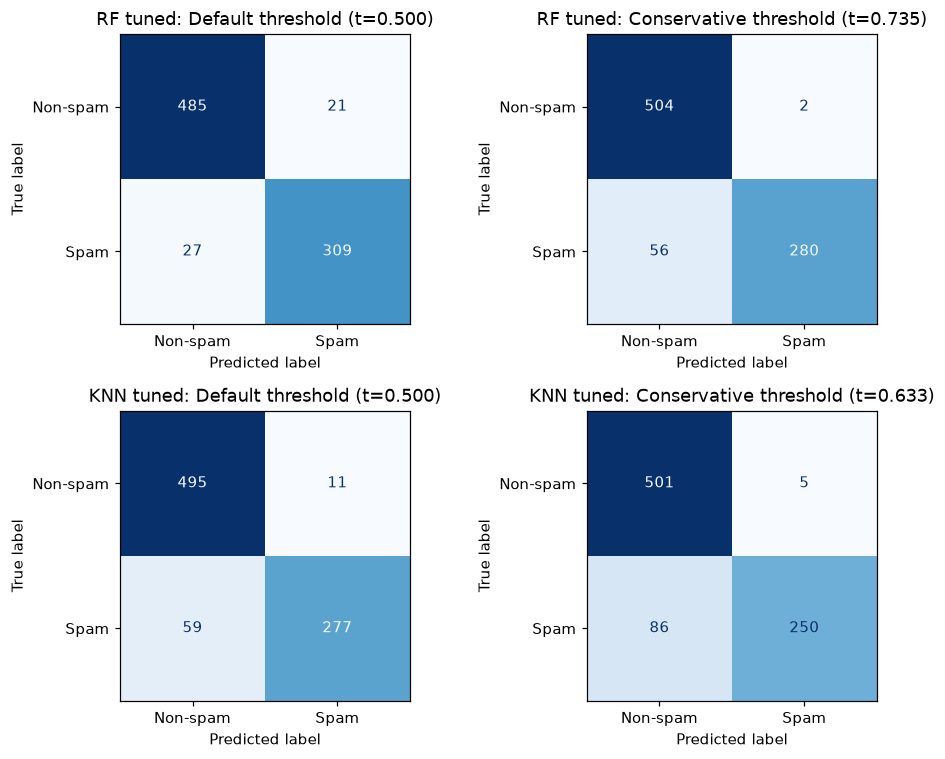

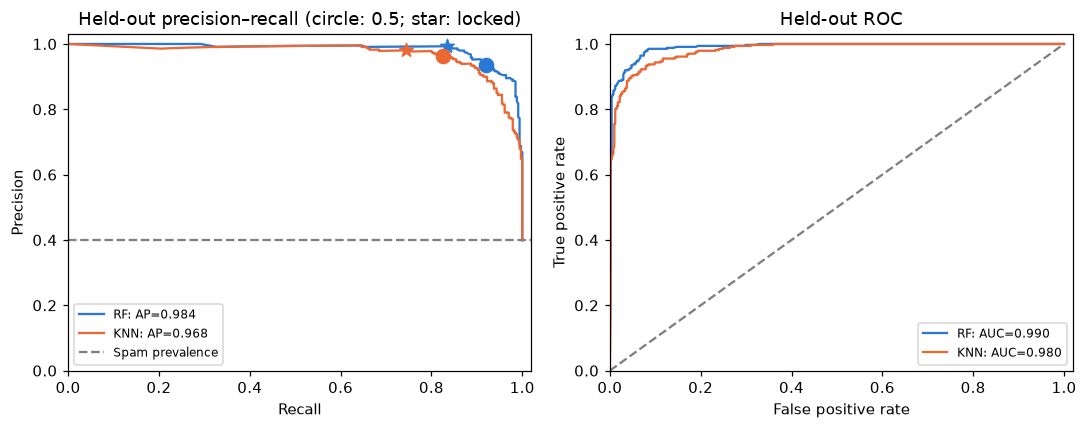

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))

for model_number, model_name in enumerate(["RF", "KNN"]):
    probabilities = test_probabilities[model_name + " tuned"]

    for policy_number in range(2):
        if policy_number == 0:
            policy = "Default"
            threshold = 0.5
        else:
            policy = "Conservative"
            threshold = thresholds[model_name]

        predicted_labels = (probabilities >= threshold).astype(int)
        ax = axes[model_number, policy_number]
        ConfusionMatrixDisplay.from_predictions(
            y_test, predicted_labels, labels=[0, 1],
            display_labels=["Non-spam", "Spam"], ax=ax,
            cmap="Blues", colorbar=False
        )
        ax.set_title(f"{model_name} tuned: {policy} threshold (t={threshold:.3f})")
        ax.grid(False)

fig.tight_layout()
save_plot("04_test_confusion_matrices.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for model_name in ["RF", "KNN"]:
    probabilities = test_probabilities[model_name + " tuned"]
    precision_values, recall_values, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    axes[0].plot(recall_values, precision_values, color=COLORS[model_name],
                 label=f"{model_name}: AP={ap:.3f}")

    for policy_number in range(2):
        if policy_number == 0:
            marker = "o"
            threshold = 0.5
        else:
            marker = "*"
            threshold = thresholds[model_name]
        scores = evaluate(y_test, probabilities, threshold)
        axes[0].scatter(scores["recall"], scores["precision"], marker=marker,
                        s=85, color=COLORS[model_name], zorder=3)

    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    axes[1].plot(false_positive_rate, true_positive_rate, color=COLORS[model_name],
                 label=f"{model_name}: AUC={auc:.3f}")

axes[0].axhline(y_test.mean(), color="gray", linestyle="--", label="Spam prevalence")
axes[0].set_title("Held-out precision–recall (circle: 0.5; star: locked)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set_title("Held-out ROC")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
for ax in axes:
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.03)
    ax.legend(fontsize=8)
fig.tight_layout()
save_plot("05_test_pr_roc.png")

## 9. Error analysis

Compare false positives and false negatives under the two thresholds. Higher thresholds can reduce false positives while missing more spam. The optional cost table uses hypothetical FP costs of 1, 2, 5 and 10, with FN cost fixed at 1; these are not measured real-world costs.

The examples show the most confident errors at threshold 0.5. Spambase has feature values but no original message text, so we cannot confirm the message content or decide that a label is wrong from the model score alone.

In [10]:
error_rows = []
cost_rows = []

for model_name in ["RF", "KNN"]:
    probabilities = test_probabilities[model_name + " tuned"]
    for policy in ["default", "conservative"]:
        if policy == "default":
            threshold = 0.5
        else:
            threshold = thresholds[model_name]

        scores = evaluate(y_test, probabilities, threshold)
        error_rows.append({"model": model_name, "policy": policy,
                           "fp": scores["fp"], "fn": scores["fn"],
                           "precision": scores["precision"], "recall": scores["recall"]})

        for fp_cost in [1, 2, 5, 10]:
            total_cost = fp_cost * scores["fp"] + scores["fn"]
            cost_rows.append({"model": model_name, "policy": policy,
                              "hypothetical_fp_cost": fp_cost, "fn_cost": 1,
                              "total_cost": total_cost})

display(pd.DataFrame(error_rows))
pd.DataFrame(cost_rows).to_csv(OUT / "hypothetical_error_costs.csv", index=False)

example_frames = []
error_frames = []
for model_name in ["RF", "KNN"]:
    probabilities = test_probabilities[model_name + " tuned"]
    predicted_labels = (probabilities >= 0.5).astype(int)

    errors = X_test.copy()
    errors.insert(0, "cleaned_row_id", errors.index)
    errors.insert(1, "model", model_name)
    errors.insert(2, "true_label", y_test.to_numpy())
    errors.insert(3, "prediction", predicted_labels)
    errors.insert(4, "spam_probability", probabilities)
    errors = errors[errors["true_label"] != errors["prediction"]]
    errors["error_type"] = "FN"
    errors.loc[errors["true_label"] == 0, "error_type"] = "FP"
    error_frames.append(errors)

    # Show three confident mistakes of each type.
    false_positives = errors[errors["error_type"] == "FP"]
    false_positives = false_positives.sort_values("spam_probability", ascending=False)
    false_negatives = errors[errors["error_type"] == "FN"]
    false_negatives = false_negatives.sort_values("spam_probability", ascending=True)
    example_frames.append(false_positives.head(3))
    example_frames.append(false_negatives.head(3))

all_errors = pd.concat(error_frames, ignore_index=True)
all_errors.to_csv(OUT / "all_default_errors.csv", index=False)
example_errors = pd.concat(example_frames, ignore_index=True)
example_errors.to_csv(OUT / "example_errors.csv", index=False)

example_columns = ["model", "cleaned_row_id", "error_type", "spam_probability",
                   "word_freq_free", "word_freq_hp", "word_freq_george",
                   "char_freq_!", "char_freq_$", "capital_run_length_total"]
display(example_errors[example_columns].round(4))

,model,policy,fp,fn,precision,recall
0,RF,default,21,27,0.936364,0.919643
1,RF,conservative,2,56,0.992908,0.833333
2,KNN,default,11,59,0.961806,0.824405
3,KNN,conservative,5,86,0.980392,0.744048


,model,cleaned_row_id,error_type,spam_probability,word_freq_free,word_freq_hp,word_freq_george,char_freq_!,char_freq_$,capital_run_length_total
0,RF,2312,FP,0.9850,0.41,0.0,0.0,0.866,0.103,485
1,RF,3027,FP,0.9050,0.00,0.0,0.0,0.000,0.665,64
2,RF,4006,FP,0.7150,0.00,0.0,0.0,0.074,0.000,246
3,RF,582,FN,0.1050,0.00,0.0,0.0,0.000,0.000,13
4,RF,162,FN,0.1200,0.00,0.0,0.0,0.000,0.000,11
5,RF,1177,FN,0.1900,0.00,0.0,0.0,0.415,0.000,42
6,KNN,2312,FP,1.0000,0.41,0.0,0.0,0.866,0.103,485
7,KNN,1876,FP,0.8092,1.72,0.0,0.0,0.000,0.000,194
8,KNN,4042,FP,0.7799,0.37,0.0,0.0,0.436,0.000,147
9,KNN,20,FN,0.0980,0.00,0.0,0.0,0.729,0.000,23


## 10. Feature interpretation

RF impurity importance describes the features used in its training splits. Permutation importance shows how test AP changes when one feature is shuffled [6]. This is a final descriptive check; it is not used to remove features or retune the model. Correlated features can affect both kinds of importance.

For KNN, inspect the five nearest training examples for one test error. Distances use the tuned model's scaled features and distance measure. The classifier may vote over more than these five neighbors.

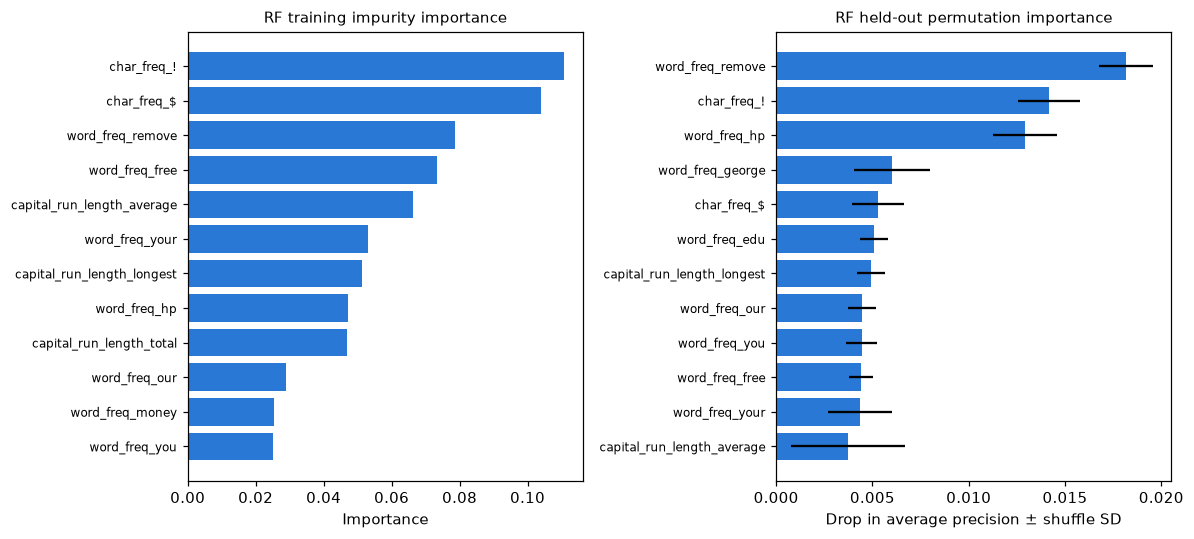

,test_cleaned_row_id,training_cleaned_row_id,distance,training_label
0,1043,2146,12.409023,0
1,1043,680,13.868409,1
2,1043,394,14.054221,1
3,1043,3131,14.279276,0
4,1043,2343,14.990804,0


Test example true label: 1


In [11]:
from sklearn.inspection import permutation_importance

rf = fitted_models["RF tuned"]
permutation = permutation_importance(
    rf, X_test, y_test, scoring="average_precision", n_repeats=5,
    random_state=RANDOM_STATE
)
importance = pd.DataFrame({
    "feature": X_train.columns,
    "impurity_importance": rf.feature_importances_,
    "permutation_ap_drop": permutation.importances_mean,
    "permutation_sd": permutation.importances_std
})
importance.to_csv(OUT / "rf_feature_importance.csv", index=False)

top_impurity = importance.nlargest(12, "impurity_importance")
top_impurity = top_impurity.sort_values("impurity_importance")
top_permutation = importance.nlargest(12, "permutation_ap_drop")
top_permutation = top_permutation.sort_values("permutation_ap_drop")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(top_impurity["feature"], top_impurity["impurity_importance"], color=COLORS["RF"])
axes[0].set_title("RF training impurity importance", fontsize=10)
axes[0].set_xlabel("Importance")
axes[1].barh(top_permutation["feature"], top_permutation["permutation_ap_drop"],
             xerr=top_permutation["permutation_sd"], color=COLORS["RF"])
axes[1].set_title("RF held-out permutation importance", fontsize=10)
axes[1].set_xlabel("Drop in average precision ± shuffle SD")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
save_plot("06_rf_importance.png")

knn = fitted_models["KNN tuned"]
knn_errors = all_errors[all_errors["model"] == "KNN"]
if len(knn_errors) > 0:
    example_id = int(knn_errors.iloc[0]["cleaned_row_id"])
else:
    example_id = int(X_test.index[0])

example_features = X_test.loc[[example_id]]
scaled_example = knn.named_steps["scale"].transform(example_features)
distances, neighbor_positions = knn.named_steps["knn"].kneighbors(scaled_example, n_neighbors=5)
training_ids = X_train.index.to_numpy()[neighbor_positions[0]]
training_labels = y_train.to_numpy()[neighbor_positions[0]]

neighbors = pd.DataFrame({"test_cleaned_row_id": example_id,
                          "training_cleaned_row_id": training_ids,
                          "distance": distances[0], "training_label": training_labels})
neighbors.to_csv(OUT / "knn_example_neighbors.csv", index=False)
display(neighbors)
print("Test example true label:", int(y_test.loc[example_id]))

## 11. Summary of findings

In [12]:
rf_results = test_results[test_results["model"] == "RF tuned"]
knn_results = test_results[test_results["model"] == "KNN tuned"]
rf_test = rf_results[rf_results["policy"] == "default 0.5"].iloc[0]
knn_test = knn_results[knn_results["policy"] == "default 0.5"].iloc[0]
rf_conservative = rf_results[rf_results["policy"] == "precision-target policy"].iloc[0]
knn_conservative = knn_results[knn_results["policy"] == "precision-target policy"].iloc[0]
rf_cv = improvements[improvements["model"] == "RF"].iloc[0]
knn_cv = improvements[improvements["model"] == "KNN"].iloc[0]

findings = f"""# Part 3 findings

Random Forest
Chosen parameters: {searches['RF'].best_params_}
Mean outer-fold AP: {rf_cv['default_mean_ap']:.4f} before tuning and {rf_cv['tuned_nested_mean_ap']:.4f} after tuning (change {rf_cv['mean_ap_change']:+.4f}).
Test at 0.5: accuracy {rf_test['accuracy']:.4f}, precision {rf_test['precision']:.4f}, recall {rf_test['recall']:.4f}, F1 {rf_test['f1']:.4f}, AP {rf_test['average_precision']:.4f}, ROC-AUC {rf_test['roc_auc']:.4f}.
Conservative threshold {thresholds['RF']:.6f}: FP/FN changed from {int(rf_test['fp'])}/{int(rf_test['fn'])} to {int(rf_conservative['fp'])}/{int(rf_conservative['fn'])}.
Conservative test precision {rf_conservative['precision']:.4f}; recall {rf_conservative['recall']:.4f}.
98% precision target met on test: {rf_conservative['precision'] >= 0.98}.

KNN
Chosen parameters: {searches['KNN'].best_params_}
Mean outer-fold AP: {knn_cv['default_mean_ap']:.4f} before tuning and {knn_cv['tuned_nested_mean_ap']:.4f} after tuning (change {knn_cv['mean_ap_change']:+.4f}).
Test at 0.5: accuracy {knn_test['accuracy']:.4f}, precision {knn_test['precision']:.4f}, recall {knn_test['recall']:.4f}, F1 {knn_test['f1']:.4f}, AP {knn_test['average_precision']:.4f}, ROC-AUC {knn_test['roc_auc']:.4f}.
Conservative threshold {thresholds['KNN']:.6f}: FP/FN changed from {int(knn_test['fp'])}/{int(knn_test['fn'])} to {int(knn_conservative['fp'])}/{int(knn_conservative['fn'])}.
Conservative test precision {knn_conservative['precision']:.4f}; recall {knn_conservative['recall']:.4f}.
98% precision target met on test: {knn_conservative['precision'] >= 0.98}.

Scaling changed default KNN mean CV AP by {scaling_change:+.4f}.

These results describe this dataset and split. Fold variation is not a significance test. A better AP does not guarantee a better F1 or recall at 0.5. Compare all metrics in the test table.

Limitations: historical data, one fixed test split, donor-specific non-spam vocabulary, conflicting labels and a finite parameter grid. Matching feature rows are grouped, but related senders or threads cannot be identified from the available features. Part 1 already explored the full dataset; the model grids here were fixed before checking test outcomes. Thresholds may behave differently on a new inbox, and the precision target is not a guarantee. No original email text is available to verify the reasons for individual errors.

Part 4 can combine test_metrics.csv and test_predictions.csv with Part 2 results from the same split.
"""
print(findings)
with open(OUT / "part3_findings.md", "w") as file:
    file.write(findings)

# Part 3 findings

Random Forest
Chosen parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
Mean outer-fold AP: 0.9763 before tuning and 0.9767 after tuning (change +0.0004).
Test at 0.5: accuracy 0.9430, precision 0.9364, recall 0.9196, F1 0.9279, AP 0.9841, ROC-AUC 0.9897.
Conservative threshold 0.735000: FP/FN changed from 21/27 to 2/56.
Conservative test precision 0.9929; recall 0.8333.
98% precision target met on test: True.

KNN
Chosen parameters: {'knn__n_neighbors': 21, 'knn__p': 1, 'knn__weights': 'distance'}
Mean outer-fold AP: 0.9072 before tuning and 0.9618 after tuning (change +0.0546).
Test at 0.5: accuracy 0.9169, precision 0.9618, recall 0.8244, F1 0.8878, AP 0.9684, ROC-AUC 0.9802.
Conservative threshold 0.633226: FP/FN changed from 11/59 to 5/86.
Conservative test precision 0.9804; recall 0.7440.
98% precision target met on test: True.

Scaling changed default KNN mean CV AP by +0.1573.

These results describe this datas

## 12. Final checks

Check that the saved predictions match the reported metrics, the scaler uses training data, and no feature group crosses the train/test split.

In [13]:
saved_predictions = pd.read_csv(OUT / "test_predictions.csv")
saved_metrics = pd.read_csv(OUT / "test_metrics.csv")

for _, result in saved_metrics.iterrows():
    probabilities = saved_predictions[result["model"] + "_probability"].to_numpy()
    checked_scores = evaluate(saved_predictions["true_label"], probabilities, result["threshold"])

    for metric_name in checked_scores:
        expected = checked_scores[metric_name]
        reported = result[metric_name]
        assert np.isclose(reported, expected, atol=1e-12, rtol=0)

    total = result["tn"] + result["fp"] + result["fn"] + result["tp"]
    assert total == len(X_test)

scaler = fitted_models["KNN tuned"].named_steps["scale"]
assert np.allclose(scaler.mean_, X_train.mean())
assert set(groups).isdisjoint(test_groups)
assert len(saved_predictions) == len(X_test)
assert saved_predictions["cleaned_row_id"].is_unique
assert not oof_table.isna().any().any()
print("All checks passed.")
print("Results saved in:", OUT)
print("Figures saved in:", FIG)

All checks passed.
Results saved in: /Users/bertasawa/CSI4810/Group Project/CSI4810/results/part3
Figures saved in: /Users/bertasawa/CSI4810/Group Project/CSI4810/figures/part3
